In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()


In [3]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten images from 28x28 to 784 features
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Train only on digit 0 (normal data)
x_train_normal = x_train[y_train == 0]

In [4]:
input_layer = Input(shape=(784,))
encoded = Dense(128, activation='relu')(input_layer)
encoded = Dense(32, activation='relu')(encoded)
latent = Dense(16, activation='relu')(encoded)

# d. Decoder reconstructs the original input
decoded = Dense(32, activation='relu')(latent)
decoded = Dense(128, activation='relu')(decoded)
output_layer = Dense(784, activation='sigmoid')(decoded)

# Build the Autoencoder
autoencoder = Model(input_layer, output_layer)

In [5]:
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

autoencoder.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 211,040 (824.38 KB)

 Trainable params: 211,040 (824.38 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = autoencoder.fit(
    x_train_normal,
    x_train_normal,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    shuffle=True
)


Epoch 1/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.1158 - mae: 0.2525 - val_loss: 0.0629 - val_mae: 0.1312
Epoch 2/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0568 - mae: 0.1226 - val_loss: 0.0505 - val_mae: 0.1131
Epoch 3/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0461 - mae: 0.1069 - val_loss: 0.0397 - val_mae: 0.0947
Epoch 4/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0386 - mae: 0.0927 - val_loss: 0.0355 - val_mae: 0.0872
Epoch 5/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0350 - mae: 0.0868 - val_loss: 0.0325 - val_mae: 0.0823
Epoch 6/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0325 - mae: 0.0821 - val_loss: 0.0311 - val_mae: 0.0791
Epoch 7/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0312 - mae: 0.0796 - val_loss: 0.0304 - val_mae: 0.0778
Epoch 8/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0303 - mae: 0.0783 - val_loss: 0.0298 - val_mae: 0.0770
Epoch 9/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0298 - mae

In [7]:
reconstructed = autoencoder.predict(x_test, verbose=0)

# Calculate reconstruction error
reconstruction_error = np.mean(
    np.square(x_test - reconstructed), axis=1
)

# Set anomaly threshold using training reconstruction errors
train_reconstructed = autoencoder.predict(
    x_train_normal, verbose=0
)
train_error = np.mean(
    np.square(x_train_normal - train_reconstructed), axis=1
)
threshold = np.percentile(train_error, 95)


Reconstruction threshold: 0.051732287
Potential anomalies: 8335
Total test images: 10000


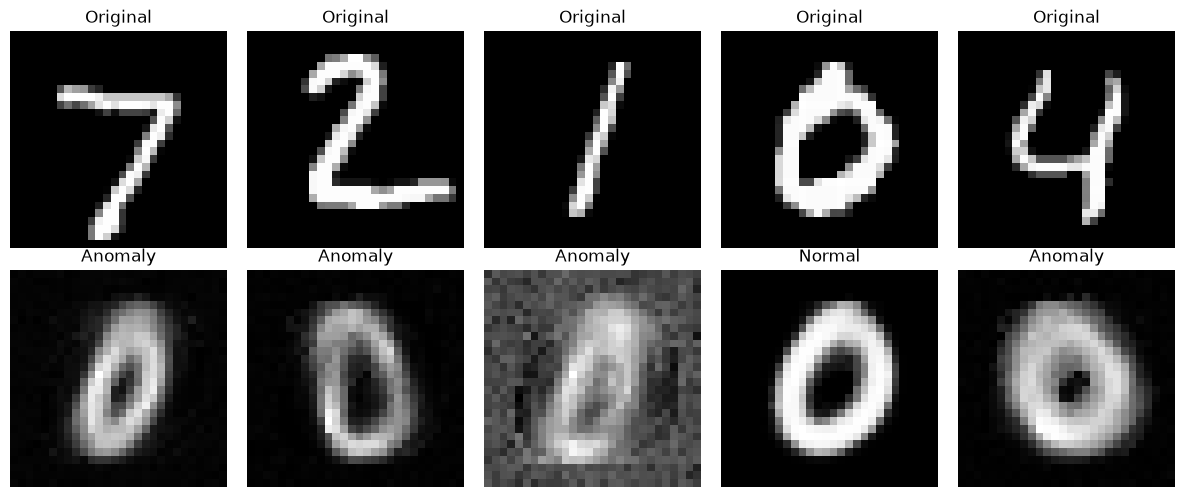

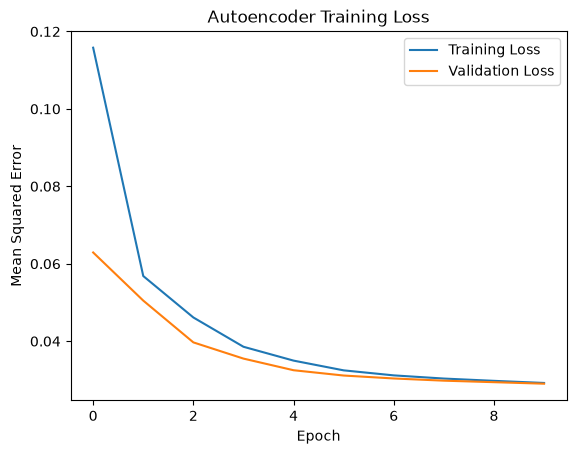

In [8]:
anomalies = reconstruction_error > threshold

print("Reconstruction threshold:", threshold)
print("Potential anomalies:", np.sum(anomalies))
print("Total test images:", len(x_test))

# Display sample results
plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 5, i + 6)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap='gray')
    label = "Anomaly" if anomalies[i] else "Normal"
    plt.title(label)
    plt.axis('off')

plt.tight_layout()
plt.show()

# Plot training loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Autoencoder Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.show()